# Image registration

Aligns each day-1 operculum ROI to the day-2 ROI of the same fish and side (SIFT features, FLANN matching, Lowe ratio test, RANSAC homography). Fish come from `data/fish_ids.csv`; aligned images go to `data/<GROUP>/images/registered/` and side-by-side plots to `registered_plots/`. Set `GROUP` to `stressed` or `misc`.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
def register_images(image1_path, image2_path):
    """
    Register image1 to image2 using SIFT feature matching and homography.

    Steps:
    1. Load both images.
    2. Convert them to grayscale.
    3. Detect SIFT keypoints and descriptors.
    4. Match descriptors using FLANN.
    5. Filter matches using Lowe's ratio test.
    6. Estimate a homography matrix with RANSAC.
    7. Warp image1 so it aligns with image2.

    Args:
        image1_path (str): Path to the image that will be aligned.
        image2_path (str): Path to the reference image.

    Returns:
        tuple:
            aligned_img (np.ndarray): image1 aligned to image2.
            reference_img (np.ndarray): original image2.
    """

    img1 = cv2.imread(image1_path)
    img2 = cv2.imread(image2_path)

    if img1 is None:
        raise FileNotFoundError(f"Could not read image: {image1_path}")

    if img2 is None:
        raise FileNotFoundError(f"Could not read image: {image2_path}")

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    sift = cv2.SIFT_create()

    keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
    keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

    if descriptors1 is None or descriptors2 is None:
        print("No descriptors found in one or both images.")
        return img1, img2

    flann_index_kdtree = 1

    index_params = {
        "algorithm": flann_index_kdtree,
        "trees": 5
    }

    search_params = {
        "checks": 50
    }

    flann = cv2.FlannBasedMatcher(index_params, search_params)

    matches = flann.knnMatch(descriptors1, descriptors2, k=2)

    good_matches = []

    for match_pair in matches:
        if len(match_pair) < 2:
            continue

        best_match, second_best_match = match_pair

        if best_match.distance < 0.75 * second_best_match.distance:
            good_matches.append(best_match)

    if len(good_matches) >= 4:
        points1 = np.float32([
            keypoints1[match.queryIdx].pt for match in good_matches
        ])

        points2 = np.float32([
            keypoints2[match.trainIdx].pt for match in good_matches
        ])

        homography_matrix, inlier_mask = cv2.findHomography(
            points1,
            points2,
            cv2.RANSAC,
            10
        )

        if homography_matrix is None:
            print("Homography could not be estimated.")
            return img1, img2

        aligned_img = cv2.warpPerspective(
            img1,
            homography_matrix,
            (img2.shape[1], img2.shape[0])
        )

        return aligned_img, img2

    else:
        print(f"Not enough good matches found: {len(good_matches)}")
        return img1, img2

----------------------------- Fish: 10 -----------------------------


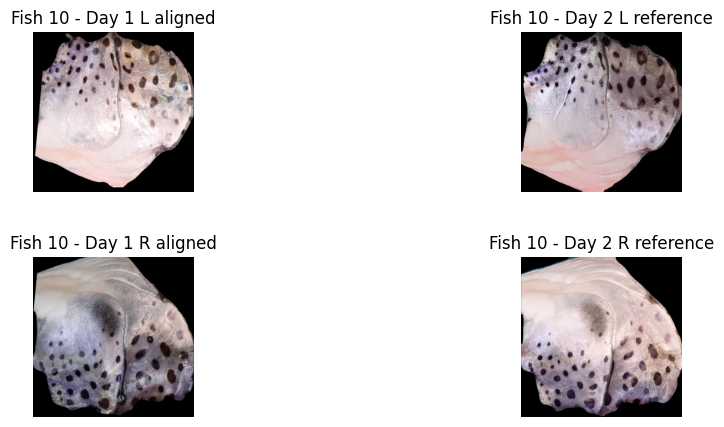

------------------------------------------------------------------------
----------------------------- Fish: 11 -----------------------------


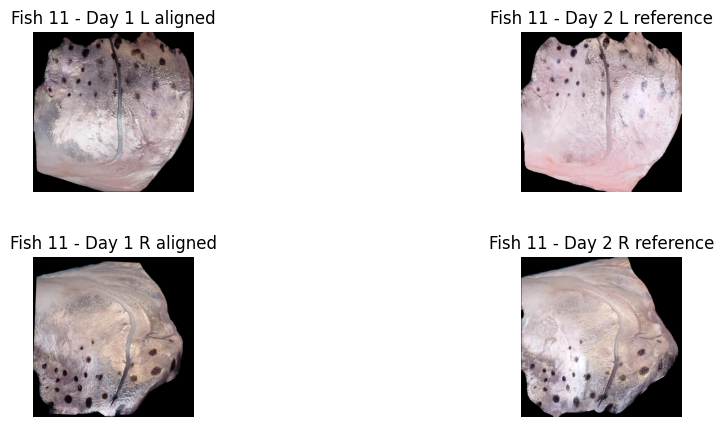

------------------------------------------------------------------------
----------------------------- Fish: 12 -----------------------------


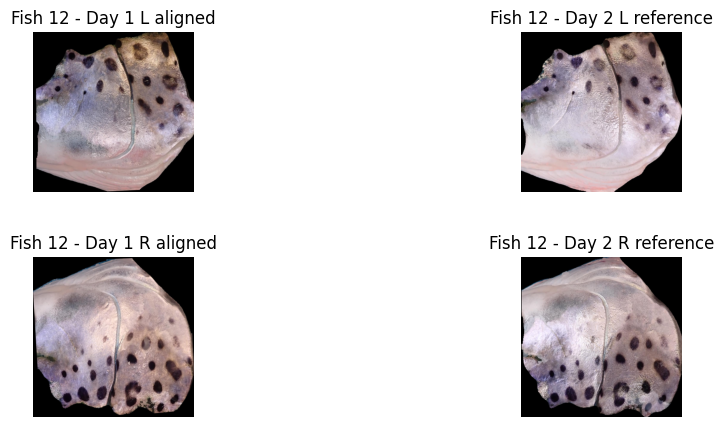

------------------------------------------------------------------------
----------------------------- Fish: 13 -----------------------------


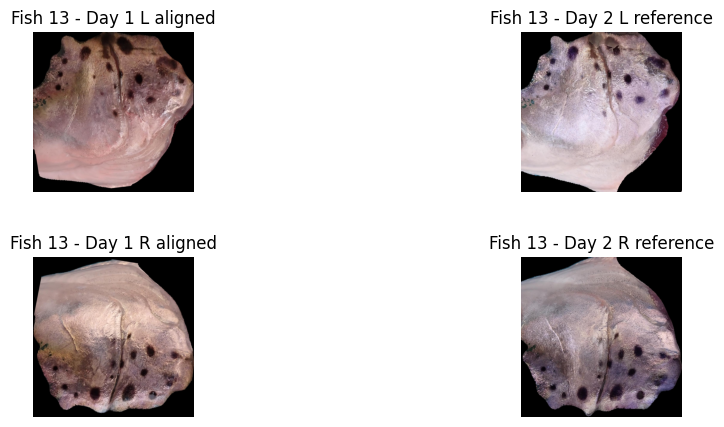

------------------------------------------------------------------------
----------------------------- Fish: 14 -----------------------------


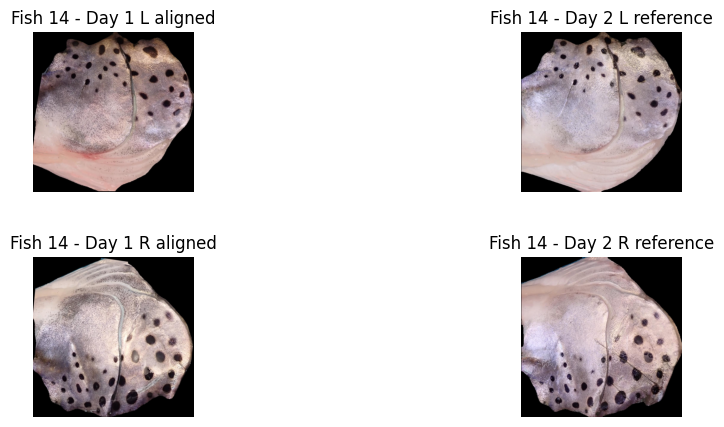

------------------------------------------------------------------------
----------------------------- Fish: 15 -----------------------------


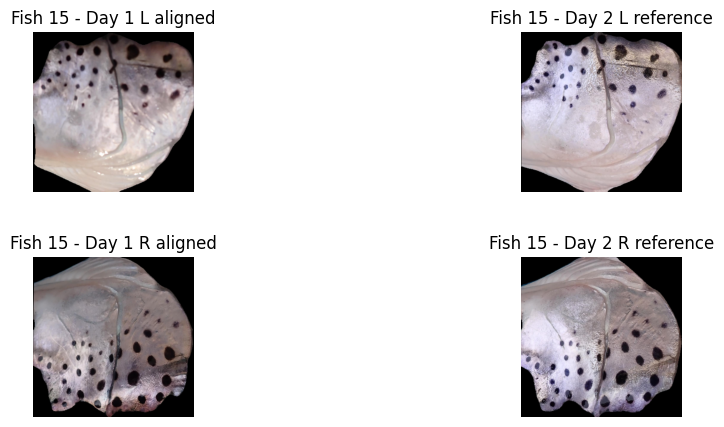

------------------------------------------------------------------------
----------------------------- Fish: 16 -----------------------------


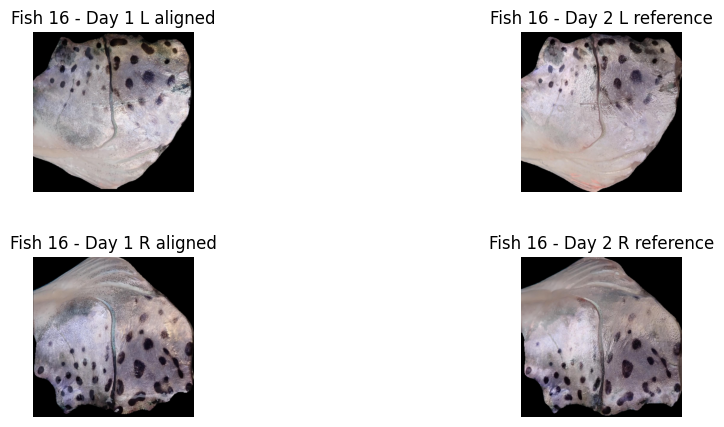

------------------------------------------------------------------------
----------------------------- Fish: 17 -----------------------------


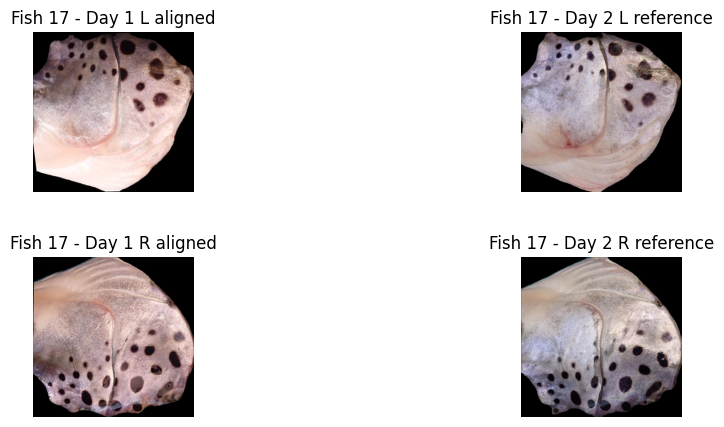

------------------------------------------------------------------------
----------------------------- Fish: 18 -----------------------------


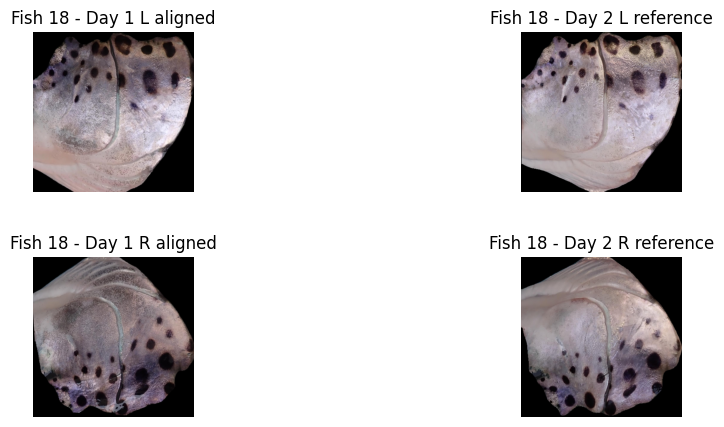

------------------------------------------------------------------------
----------------------------- Fish: 19 -----------------------------


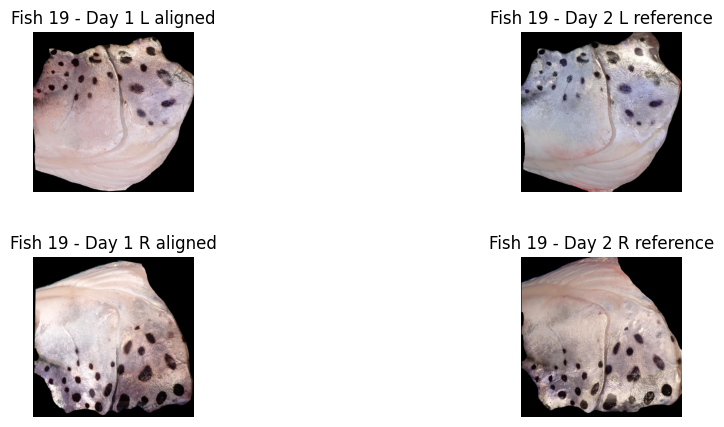

------------------------------------------------------------------------
----------------------------- Fish: 20 -----------------------------


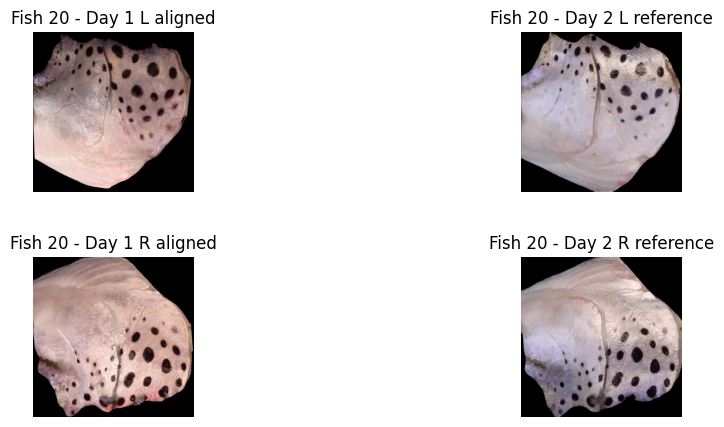

------------------------------------------------------------------------
----------------------------- Fish: 21 -----------------------------


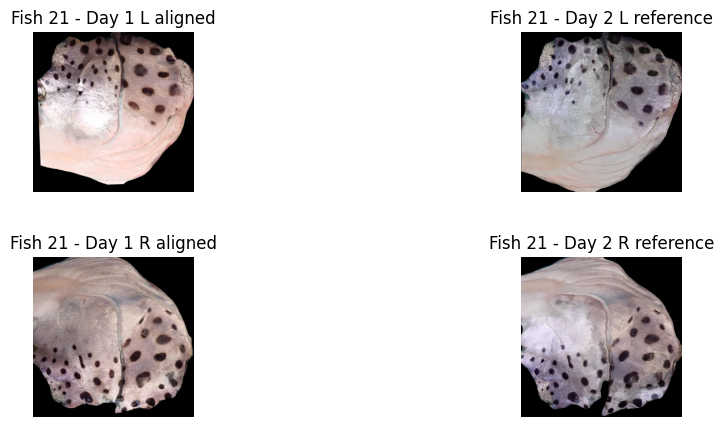

------------------------------------------------------------------------
----------------------------- Fish: 22 -----------------------------


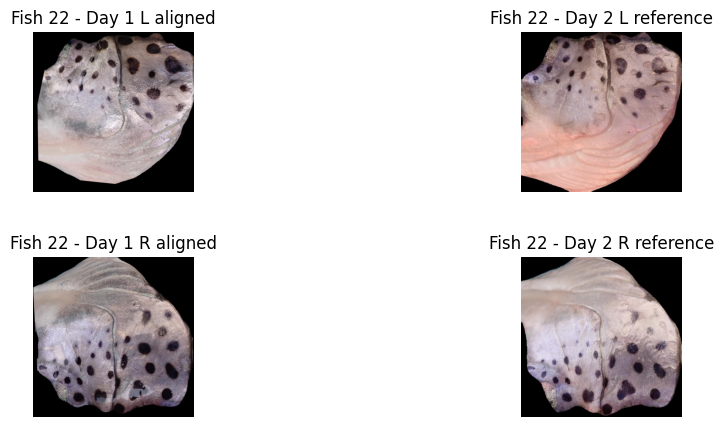

------------------------------------------------------------------------
----------------------------- Fish: 23 -----------------------------


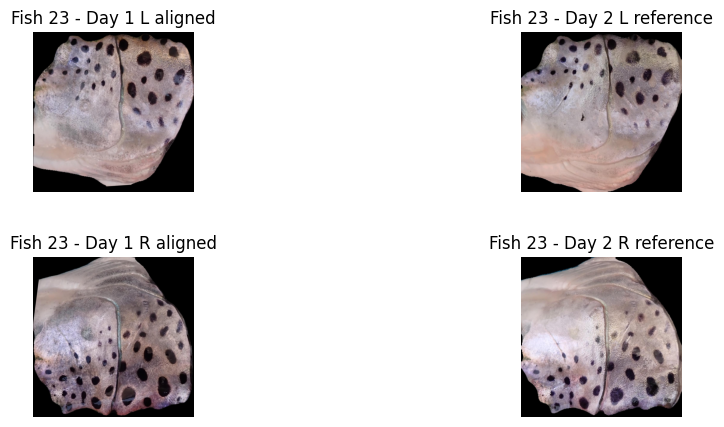

------------------------------------------------------------------------
----------------------------- Fish: 24 -----------------------------


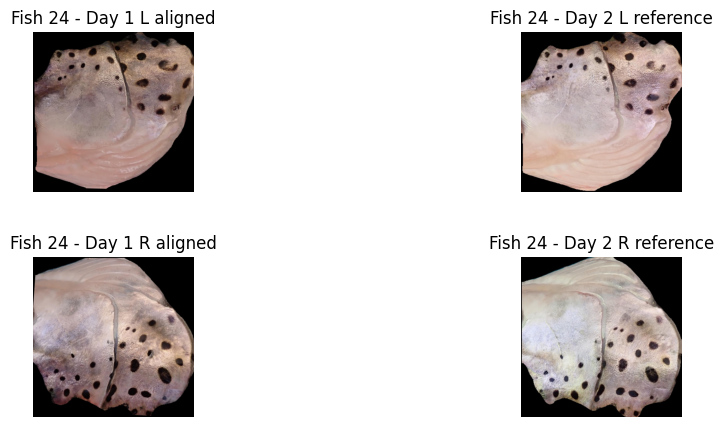

------------------------------------------------------------------------
----------------------------- Fish: 25 -----------------------------


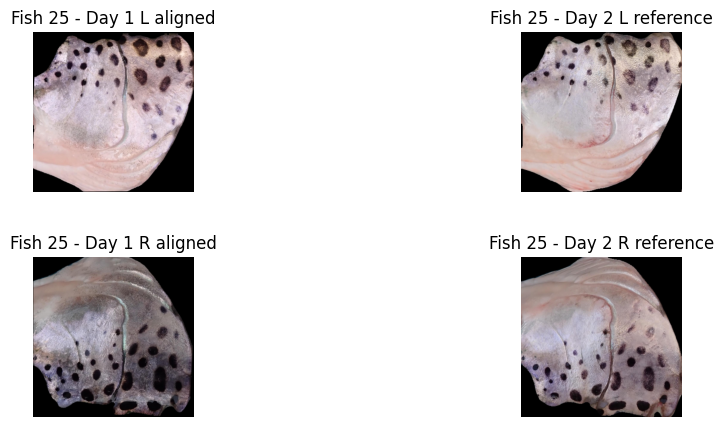

------------------------------------------------------------------------
----------------------------- Fish: 26 -----------------------------


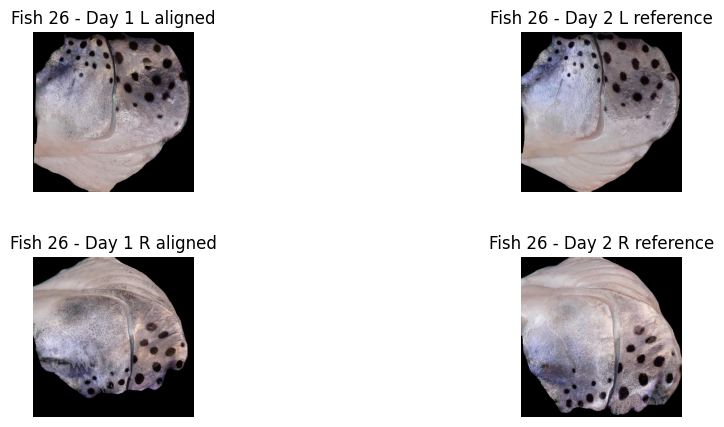

------------------------------------------------------------------------
----------------------------- Fish: 27 -----------------------------


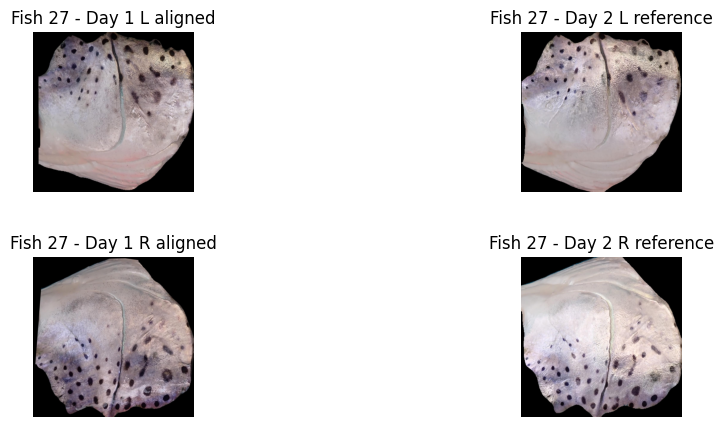

------------------------------------------------------------------------
----------------------------- Fish: 28 -----------------------------


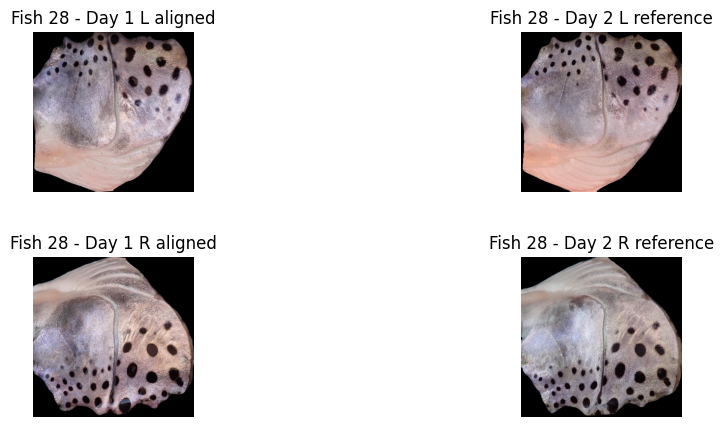

------------------------------------------------------------------------
----------------------------- Fish: 29 -----------------------------


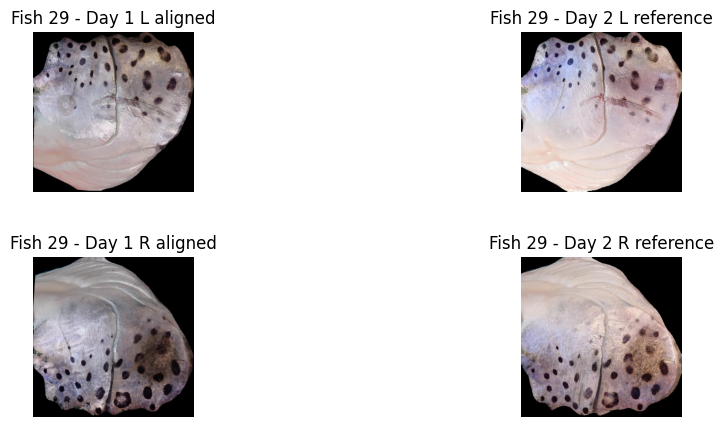

------------------------------------------------------------------------
----------------------------- Fish: 30 -----------------------------


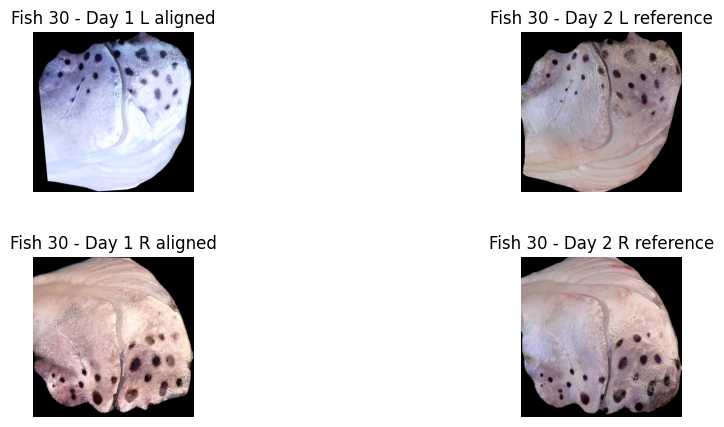

------------------------------------------------------------------------
----------------------------- Fish: 31 -----------------------------


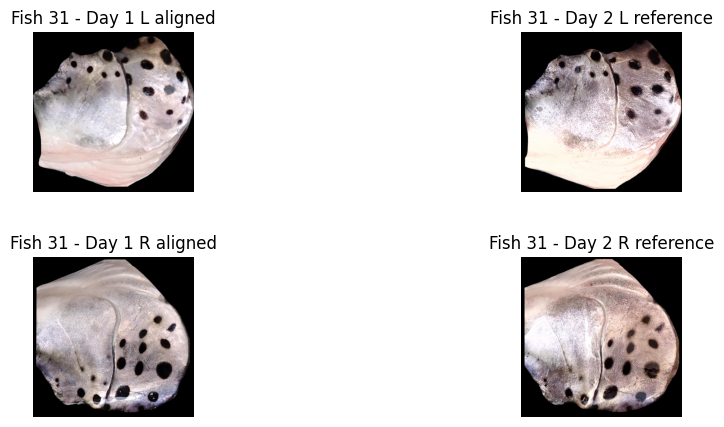

------------------------------------------------------------------------
----------------------------- Fish: 32 -----------------------------


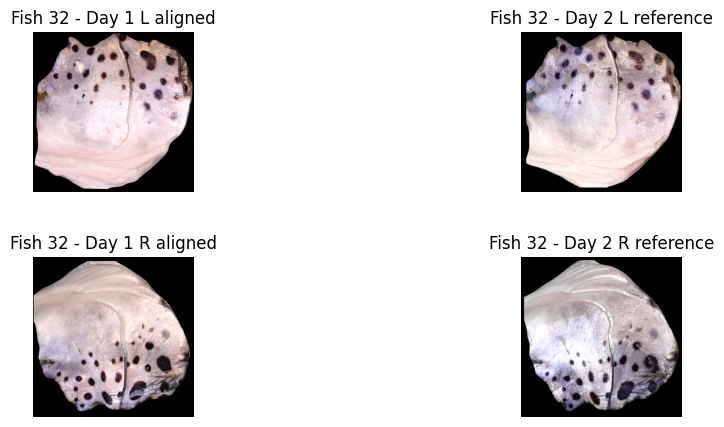

------------------------------------------------------------------------
----------------------------- Fish: 33 -----------------------------


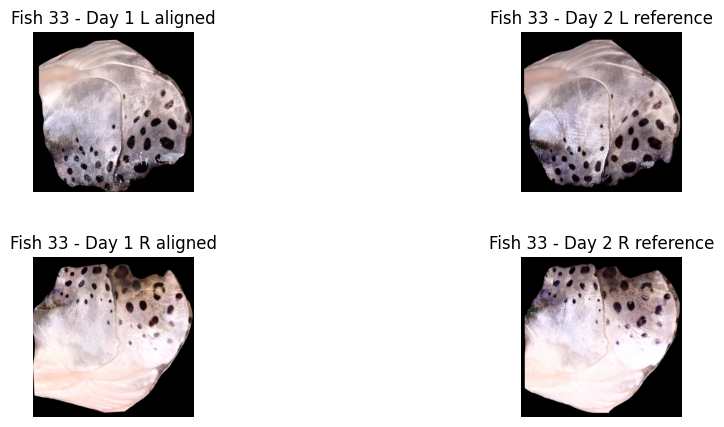

------------------------------------------------------------------------
----------------------------- Fish: 34 -----------------------------


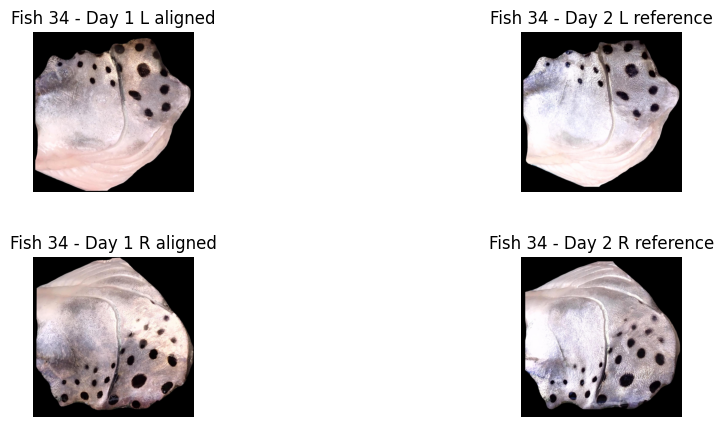

------------------------------------------------------------------------
----------------------------- Fish: 35 -----------------------------


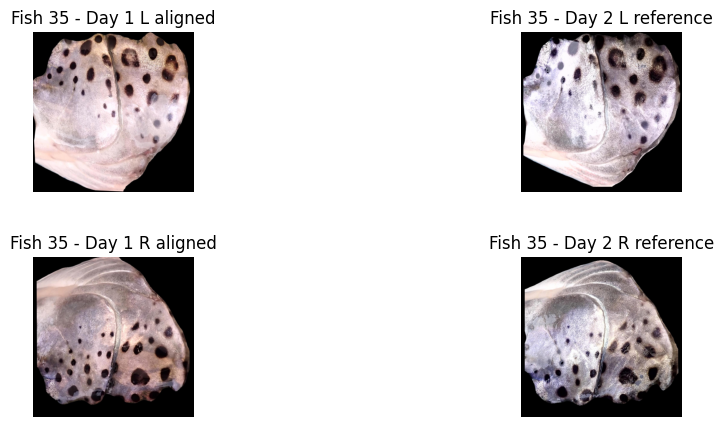

------------------------------------------------------------------------
----------------------------- Fish: 36 -----------------------------


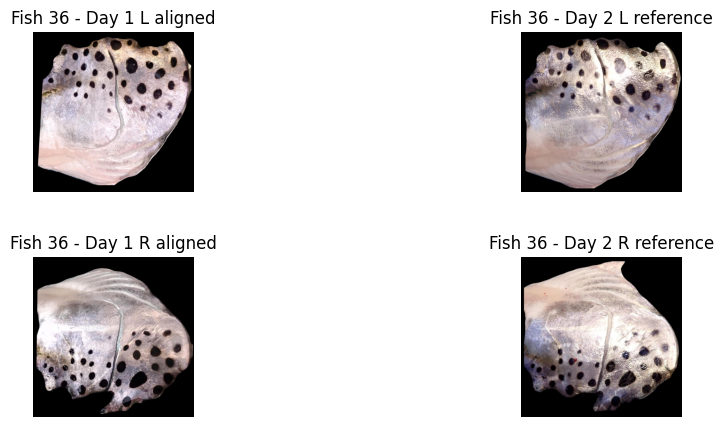

------------------------------------------------------------------------
----------------------------- Fish: 37 -----------------------------


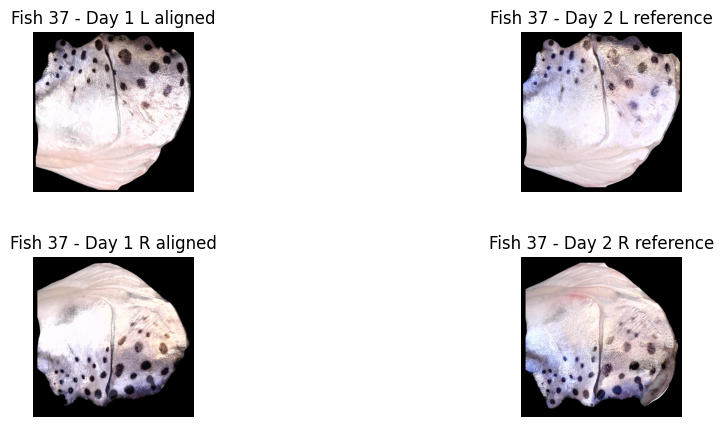

------------------------------------------------------------------------
----------------------------- Fish: 38 -----------------------------


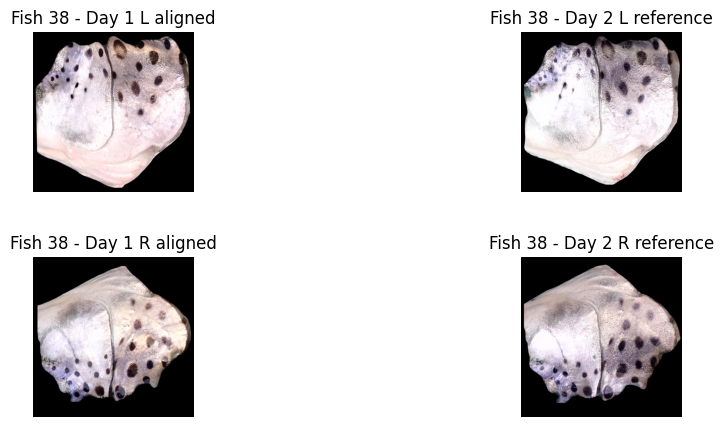

------------------------------------------------------------------------
----------------------------- Fish: 39 -----------------------------


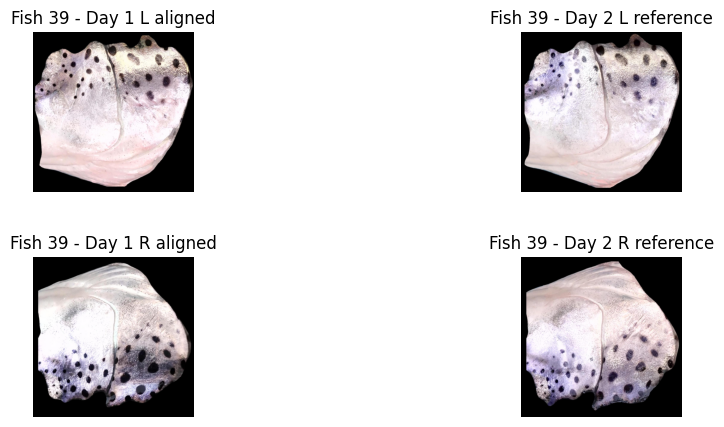

------------------------------------------------------------------------
----------------------------- Fish: 40 -----------------------------


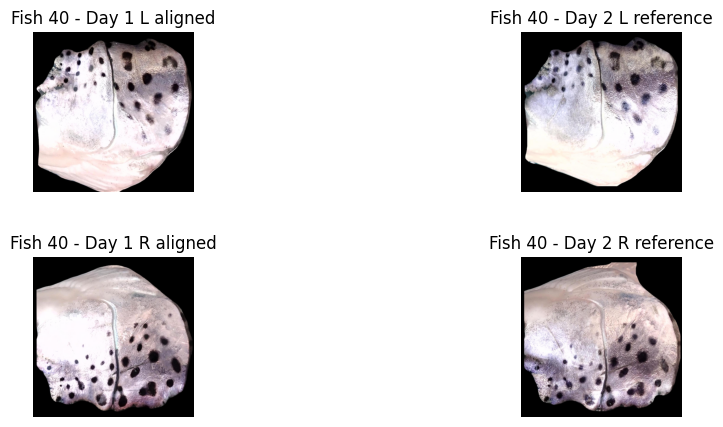

------------------------------------------------------------------------
----------------------------- Fish: 41 -----------------------------


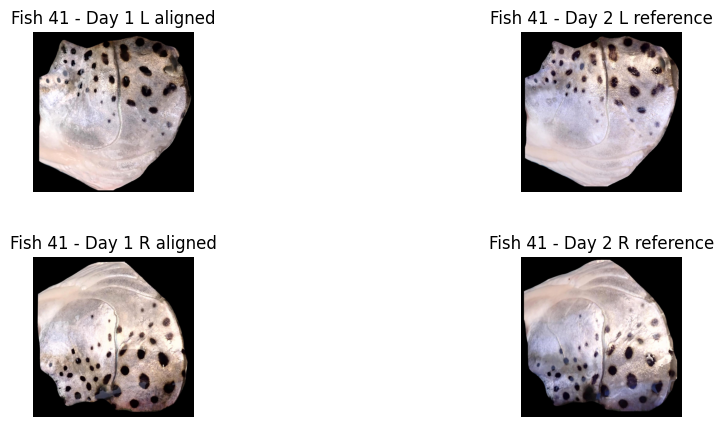

------------------------------------------------------------------------
----------------------------- Fish: 42 -----------------------------


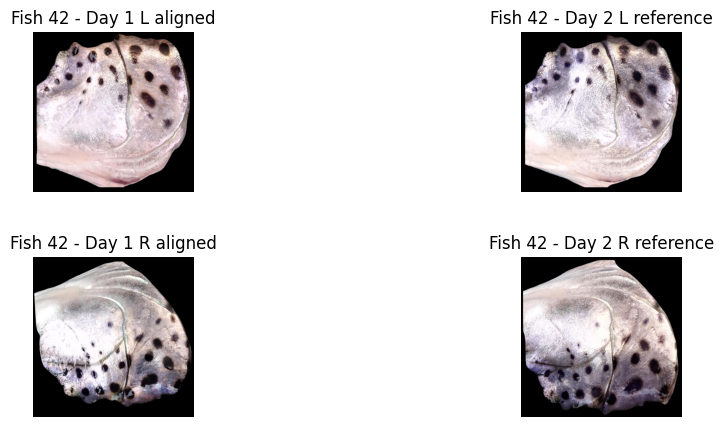

------------------------------------------------------------------------
----------------------------- Fish: 43 -----------------------------


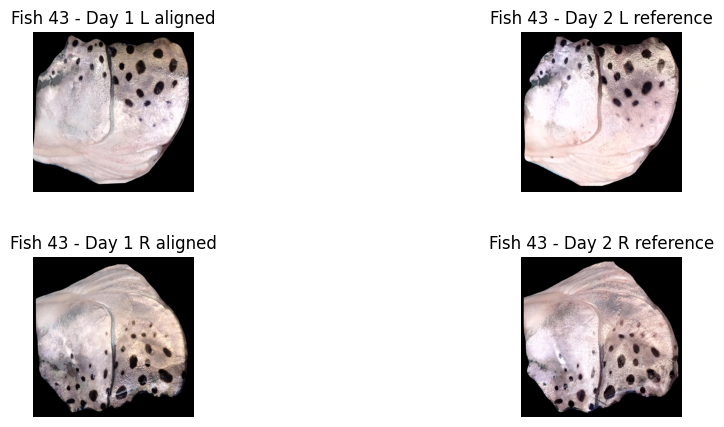

------------------------------------------------------------------------
----------------------------- Fish: 44 -----------------------------


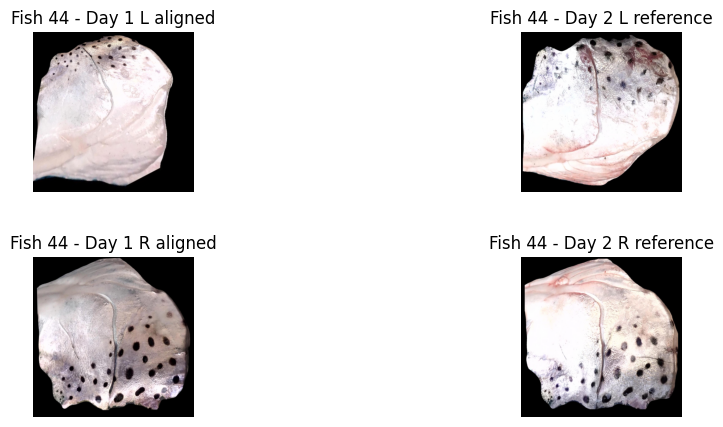

------------------------------------------------------------------------
----------------------------- Fish: 45 -----------------------------


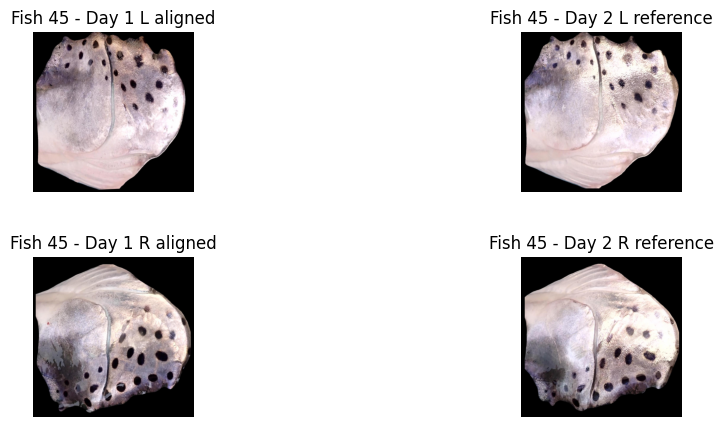

------------------------------------------------------------------------
----------------------------- Fish: 46 -----------------------------


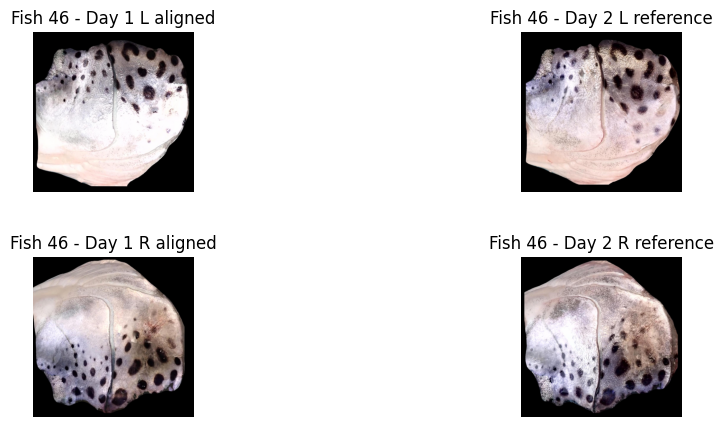

------------------------------------------------------------------------
----------------------------- Fish: 47 -----------------------------


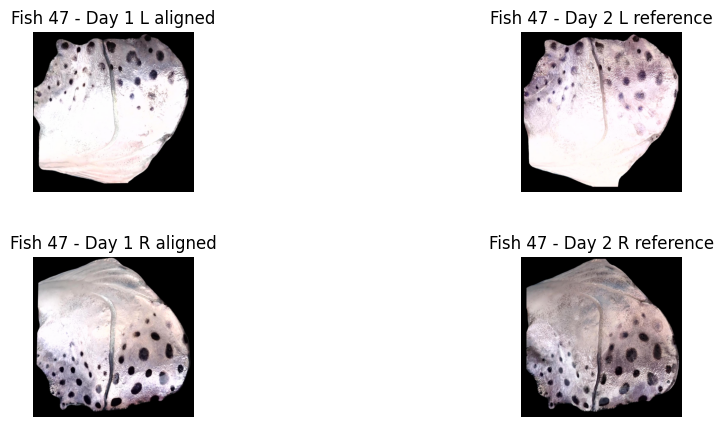

------------------------------------------------------------------------
----------------------------- Fish: 48 -----------------------------


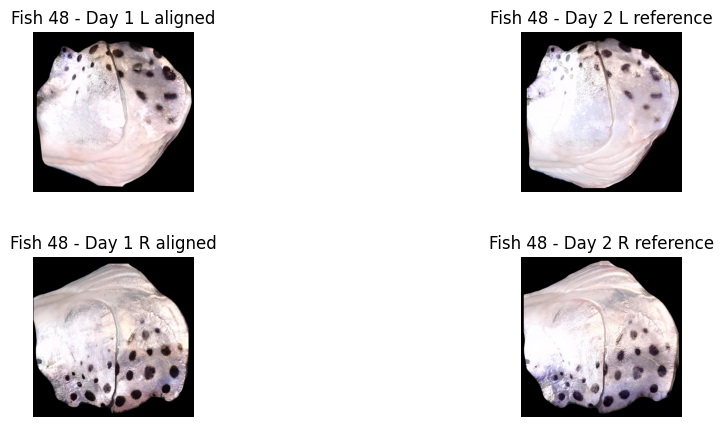

------------------------------------------------------------------------
----------------------------- Fish: 49 -----------------------------


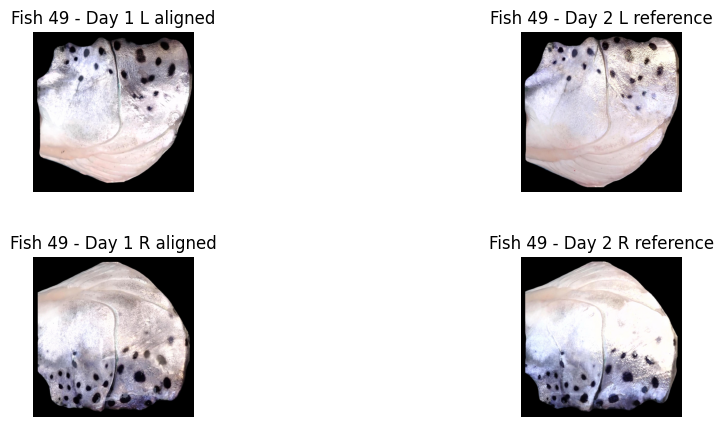

------------------------------------------------------------------------
----------------------------- Fish: 50 -----------------------------


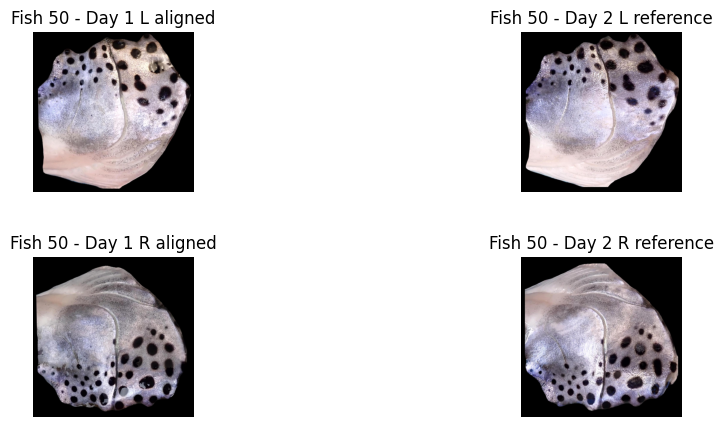

------------------------------------------------------------------------
----------------------------- Fish: 51 -----------------------------


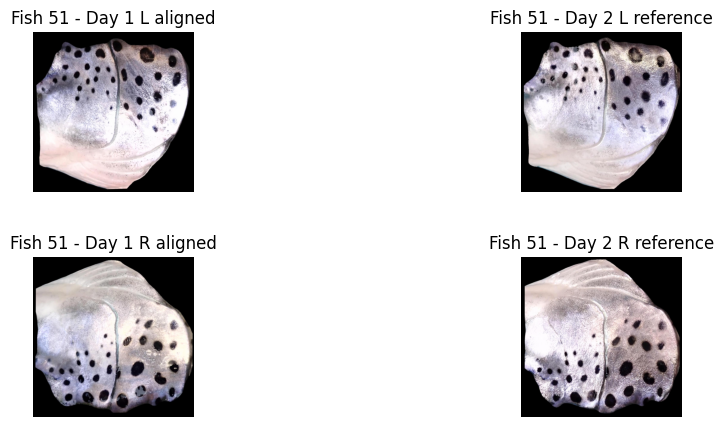

------------------------------------------------------------------------
----------------------------- Fish: 52 -----------------------------


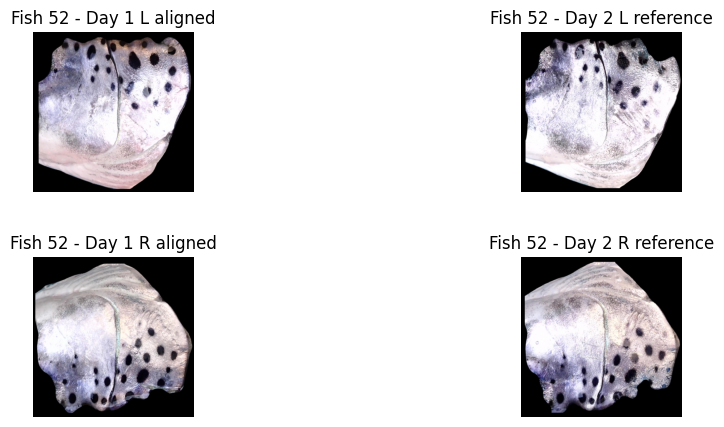

------------------------------------------------------------------------
----------------------------- Fish: 53 -----------------------------


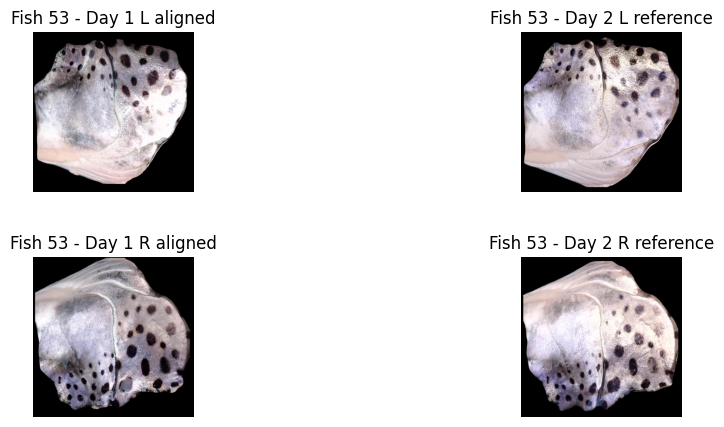

------------------------------------------------------------------------
----------------------------- Fish: 54 -----------------------------


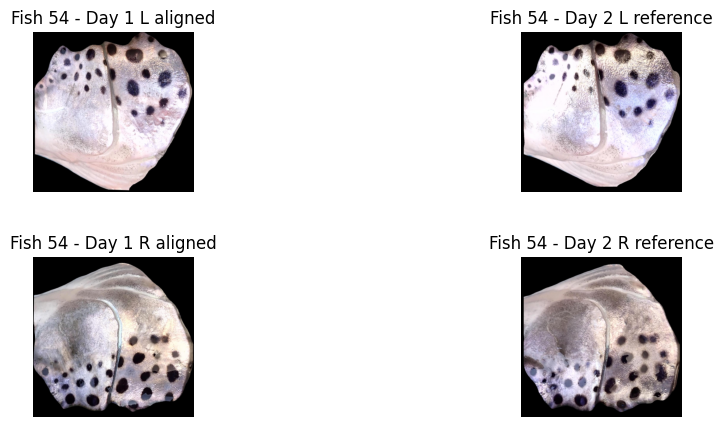

------------------------------------------------------------------------
----------------------------- Fish: 55 -----------------------------


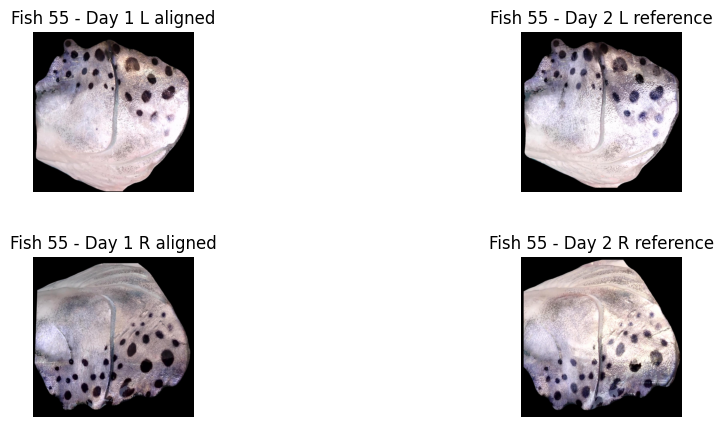

------------------------------------------------------------------------
----------------------------- Fish: 56 -----------------------------


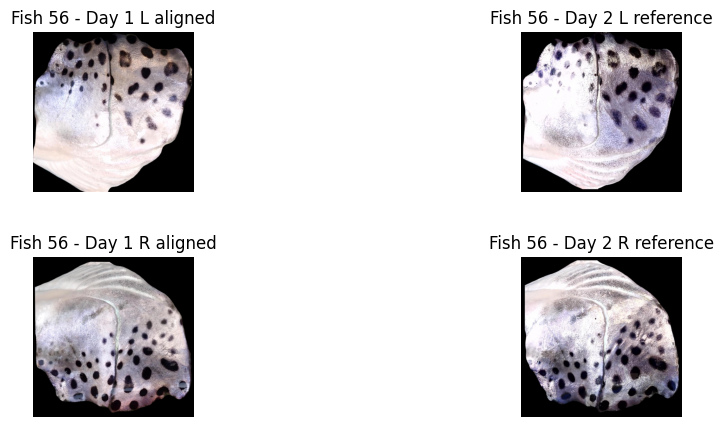

------------------------------------------------------------------------
----------------------------- Fish: 57 -----------------------------


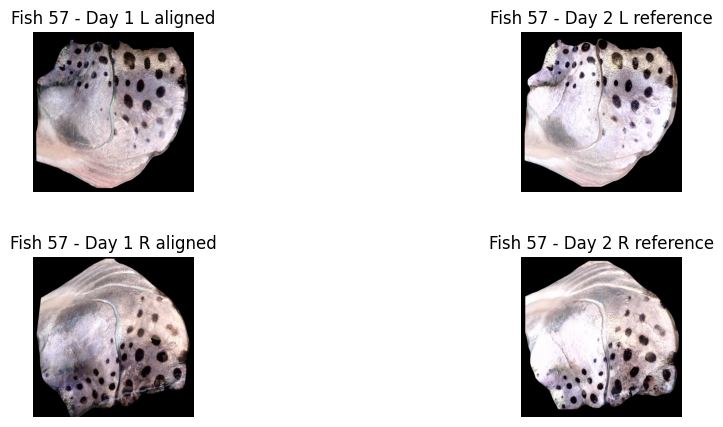

------------------------------------------------------------------------
----------------------------- Fish: 58 -----------------------------


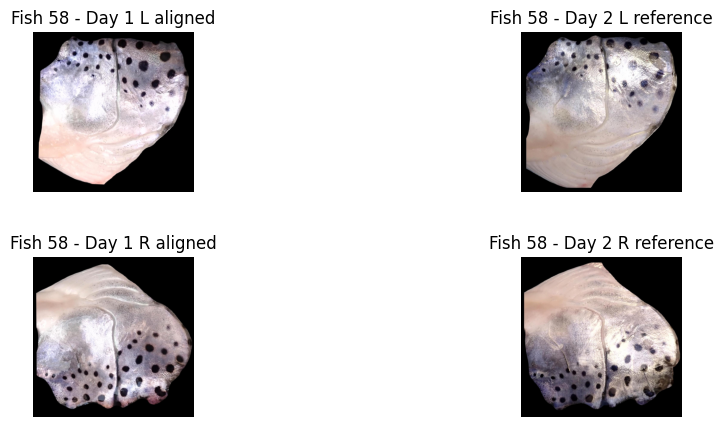

------------------------------------------------------------------------
----------------------------- Fish: 59 -----------------------------


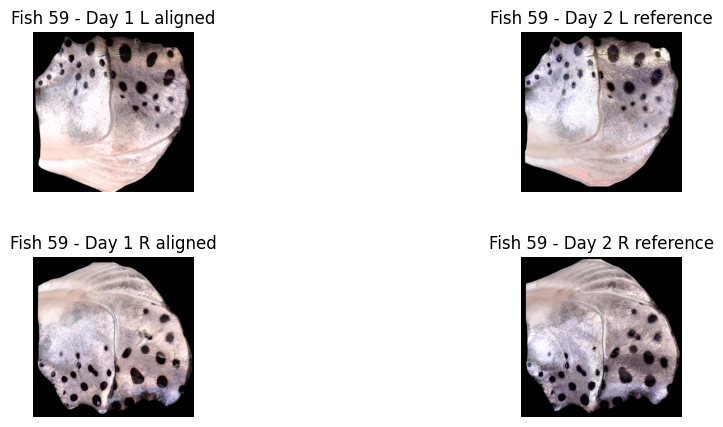

------------------------------------------------------------------------
----------------------------- Fish: 60 -----------------------------


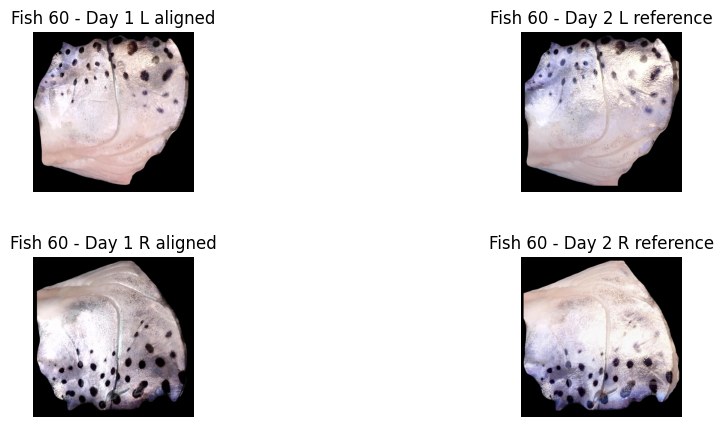

------------------------------------------------------------------------
----------------------------- Fish: 61 -----------------------------


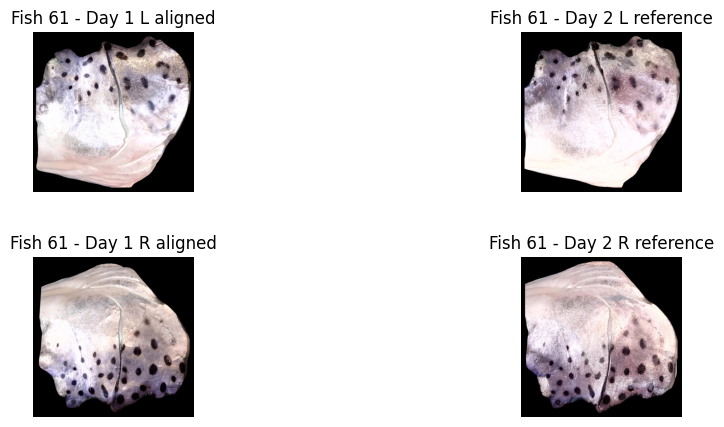

------------------------------------------------------------------------
----------------------------- Fish: 62 -----------------------------


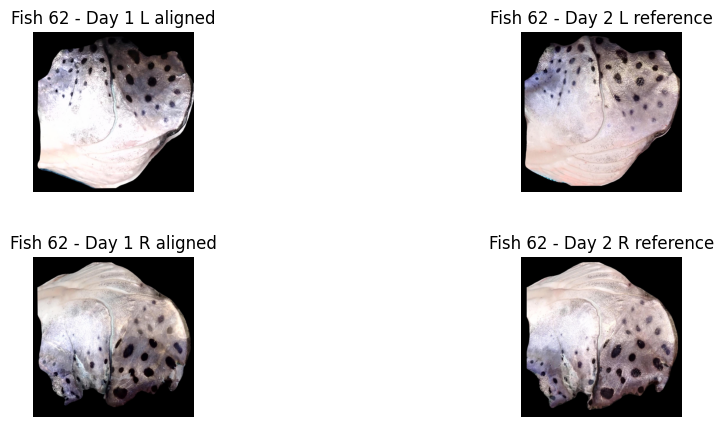

------------------------------------------------------------------------
----------------------------- Fish: 63 -----------------------------


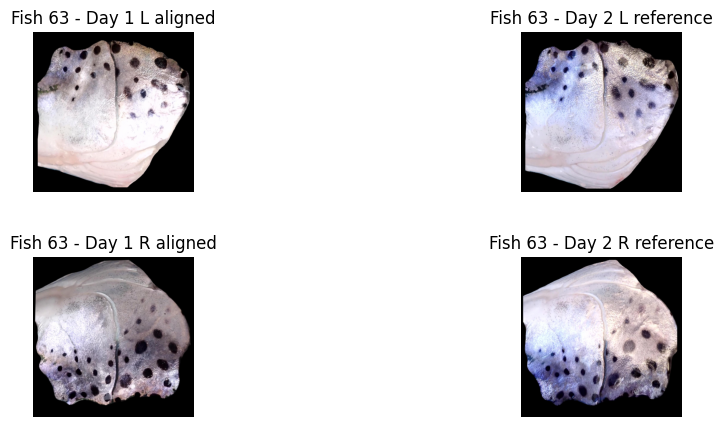

------------------------------------------------------------------------
----------------------------- Fish: 64 -----------------------------


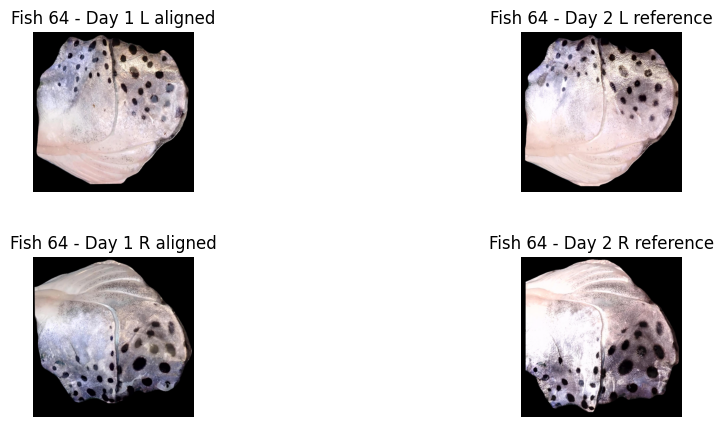

------------------------------------------------------------------------
----------------------------- Fish: 65 -----------------------------


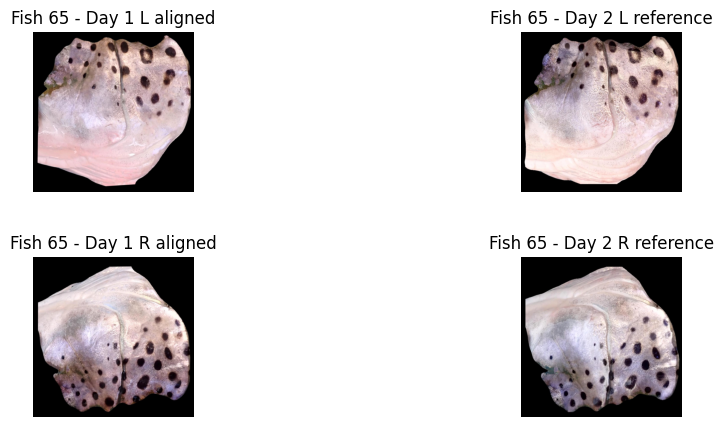

------------------------------------------------------------------------
----------------------------- Fish: 66 -----------------------------


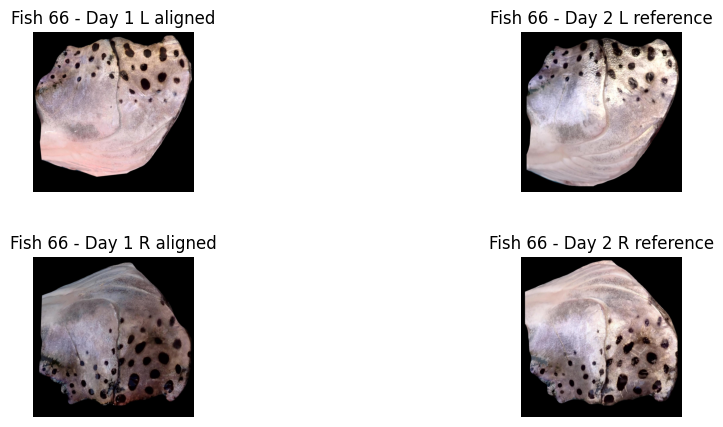

------------------------------------------------------------------------
----------------------------- Fish: 67 -----------------------------


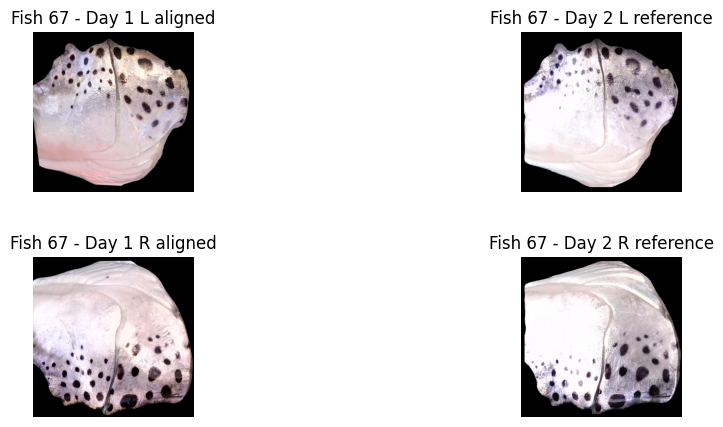

------------------------------------------------------------------------
----------------------------- Fish: 68 -----------------------------


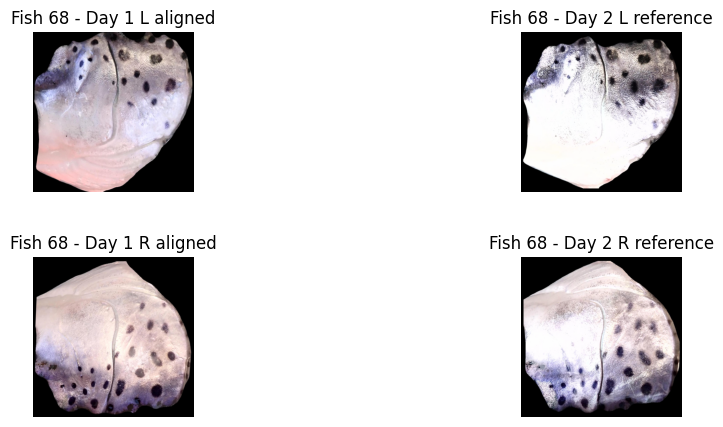

------------------------------------------------------------------------
----------------------------- Fish: 69 -----------------------------


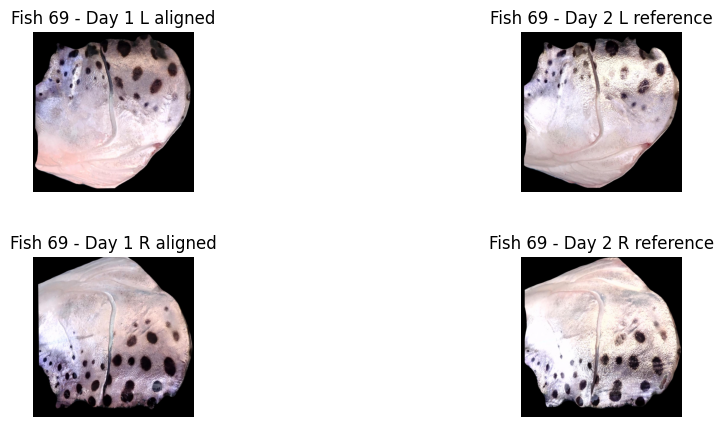

------------------------------------------------------------------------
----------------------------- Fish: 70 -----------------------------


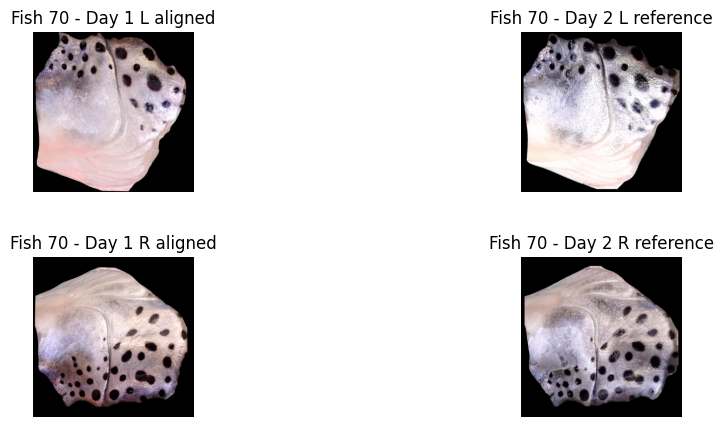

------------------------------------------------------------------------
----------------------------- Fish: 71 -----------------------------


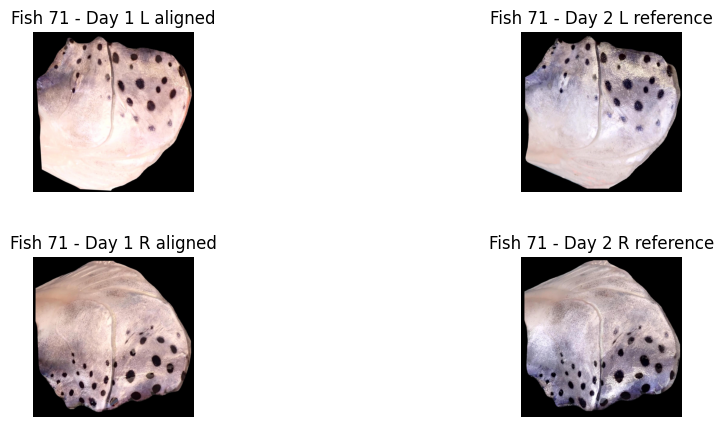

------------------------------------------------------------------------
----------------------------- Fish: 72 -----------------------------


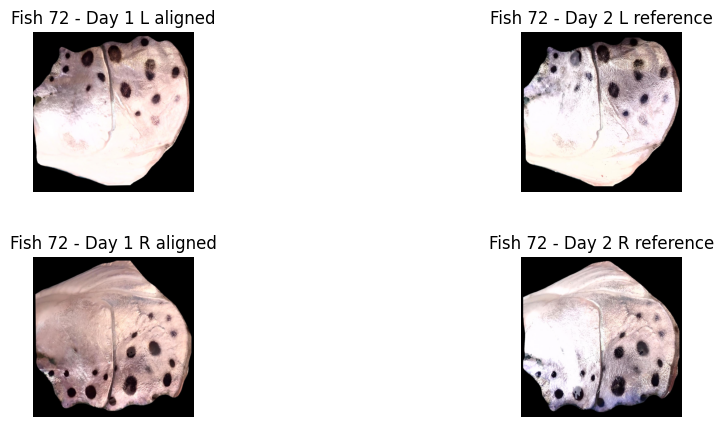

------------------------------------------------------------------------
----------------------------- Fish: 73 -----------------------------


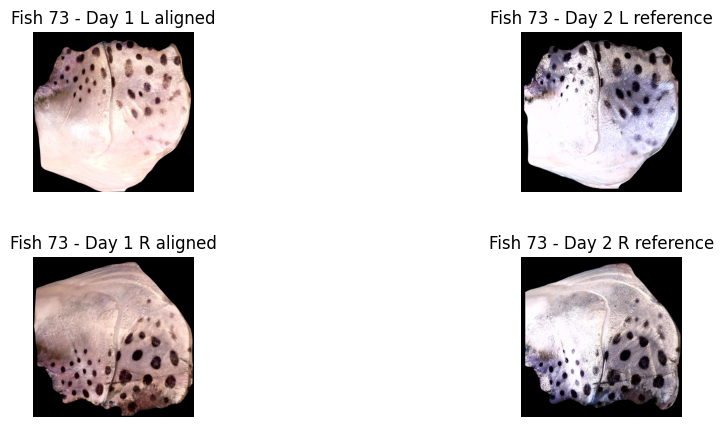

------------------------------------------------------------------------
----------------------------- Fish: 74 -----------------------------


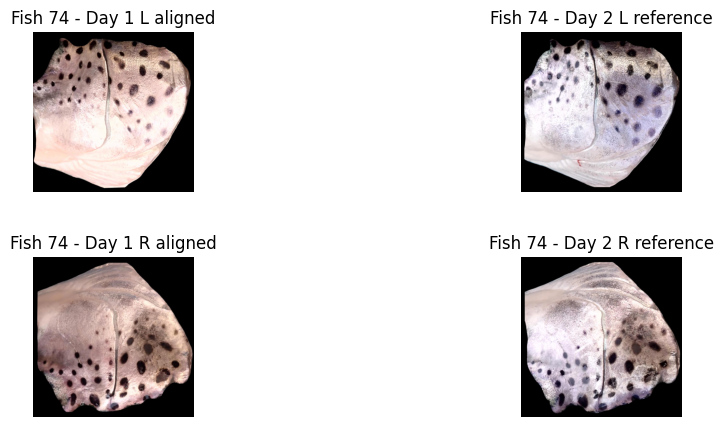

------------------------------------------------------------------------
----------------------------- Fish: 75 -----------------------------


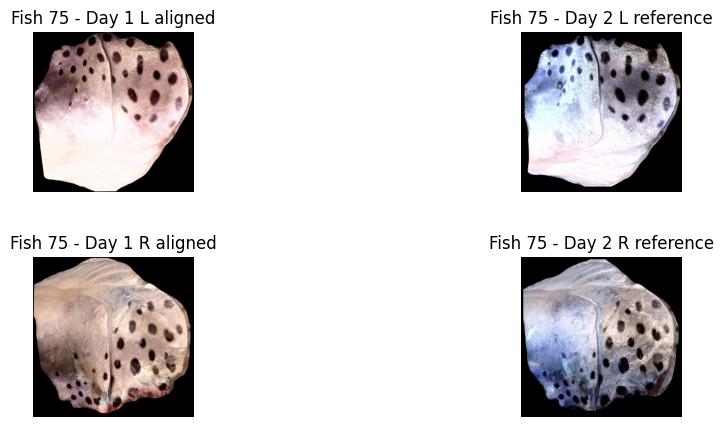

------------------------------------------------------------------------
----------------------------- Fish: 76 -----------------------------


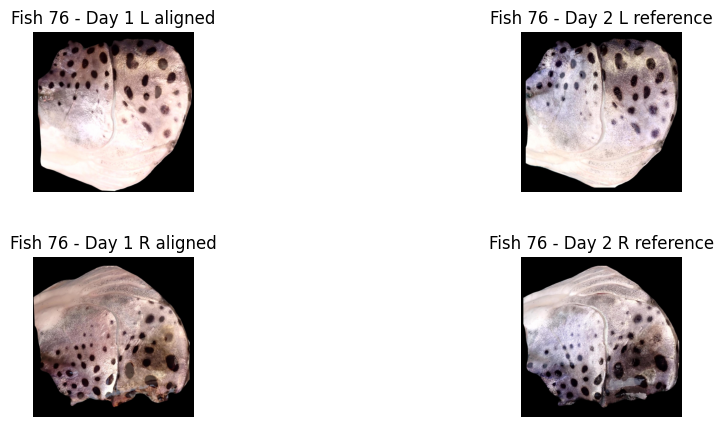

------------------------------------------------------------------------


In [4]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "fish_ids.csv").is_file())
GROUP = "stressed"
DATA = ROOT / "data" / GROUP

fish_ids = pd.read_csv(ROOT / "data" / "fish_ids.csv", index_col=False)
fish_name = [(v[0], v[1], v[2]) for v in fish_ids.values]

images_path = DATA / "images" / "operculum_images"

registered_path = DATA / "images" / "registered"
registered_plots = DATA / "images" / "registered_plots"

os.makedirs(registered_path, exist_ok=True)
os.makedirs(registered_plots, exist_ok=True)


for fish_id, day1_id, day2_id in fish_name:
    print(f"----------------------------- Fish: {fish_id} -----------------------------")

    day1_left_path = os.path.join(
        images_path,
        f"fish_{fish_id}_S_day1_id-{day1_id}_L_h.jpg"
    )

    day2_left_path = os.path.join(
        images_path,
        f"fish_{fish_id}_S_day2_id-{day2_id}_L_h.jpg"
    )

    day1_right_path = os.path.join(
        images_path,
        f"fish_{fish_id}_S_day1_id-{day1_id}_R_h.jpg"
    )

    day2_right_path = os.path.join(
        images_path,
        f"fish_{fish_id}_S_day2_id-{day2_id}_R_h.jpg"
    )

    if not all(os.path.exists(p) for p in (day1_left_path, day2_left_path, day1_right_path, day2_right_path)):
        print(f"Fish {fish_id}: not in group '{GROUP}', skipped")
        continue

    aligned_day1_left, day2_left = register_images(
        day1_left_path,
        day2_left_path
    )

    aligned_day1_right, day2_right = register_images(
        day1_right_path,
        day2_right_path
    )

    cv2.imwrite(
        os.path.join(
            registered_path,
            f"fish_{fish_id}_S_day1_id-{day1_id}_L_h.jpg"
        ),
        aligned_day1_left
    )

    cv2.imwrite(
        os.path.join(
            registered_path,
            f"fish_{fish_id}_S_day2_id-{day2_id}_L_h.jpg"
        ),
        day2_left
    )

    cv2.imwrite(
        os.path.join(
            registered_path,
            f"fish_{fish_id}_S_day1_id-{day1_id}_R_h.jpg"
        ),
        aligned_day1_right
    )

    cv2.imwrite(
        os.path.join(
            registered_path,
            f"fish_{fish_id}_S_day2_id-{day2_id}_R_h.jpg"
        ),
        day2_right
    )

    aligned_day1_left_rgb = cv2.cvtColor(aligned_day1_left, cv2.COLOR_BGR2RGB)
    day2_left_rgb = cv2.cvtColor(day2_left, cv2.COLOR_BGR2RGB)

    aligned_day1_right_rgb = cv2.cvtColor(aligned_day1_right, cv2.COLOR_BGR2RGB)
    day2_right_rgb = cv2.cvtColor(day2_right, cv2.COLOR_BGR2RGB)

    fig, axs = plt.subplots(2, 2, figsize=(10, 5))
    fig.subplots_adjust(hspace=0.4, wspace=0.7)

    axs[0, 0].imshow(aligned_day1_left_rgb)
    axs[0, 0].set_title(f"Fish {fish_id} - Day 1 L aligned")
    axs[0, 0].axis("off")

    axs[0, 1].imshow(day2_left_rgb)
    axs[0, 1].set_title(f"Fish {fish_id} - Day 2 L reference")
    axs[0, 1].axis("off")

    axs[1, 0].imshow(aligned_day1_right_rgb)
    axs[1, 0].set_title(f"Fish {fish_id} - Day 1 R aligned")
    axs[1, 0].axis("off")

    axs[1, 1].imshow(day2_right_rgb)
    axs[1, 1].set_title(f"Fish {fish_id} - Day 2 R reference")
    axs[1, 1].axis("off")

    plt.savefig(
        os.path.join(
            registered_plots,
            f"fish_{fish_id}_reg.jpg"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("------------------------------------------------------------------------")